# Day 4 – Delivery Time Prediction

### Business objective
Build regression models to estimate how long an order will take to be delivered. This can help an operations team understand delivery-time patterns and produce more consistent estimates.

## 1. Import libraries

We use pandas and NumPy for data handling, Matplotlib and Seaborn for charts, scikit-learn for preprocessing and regression, and joblib to save the final model pipeline.

In [1]:
# Import tools for data handling, visualization, modeling, evaluation, and saving.
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme()
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the project datasets

It loads delivery data first because delivery duration is our target. Orders, restaurants, and customers are optional sources of additional features.

In [2]:
# Locate the project root relative to the current working directory.
CANDIDATE_ROOTS = [Path.cwd(), Path.cwd().parent]
project_root = next((root for root in CANDIDATE_ROOTS if (root / "data").exists()), None)

if project_root is None:
    raise FileNotFoundError(
        "Could not find the project data folder. Run this notebook from the repository root "
        "or from the notebooks folder."
    )

raw_dir = project_root / "data" / "raw"
processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models" / "day4"
reports_dir = project_root / "reports" / "day4"

# Create output folders if needed.
processed_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

def load_csv_if_present(filename):
    # Return None for an optional file that is not present.
    path = raw_dir / filename
    if path.exists():
        return pd.read_csv(path)
    print(f"Optional dataset not found: {path}")
    return None

deliveries_df = load_csv_if_present("deliveries.csv")
orders_df = load_csv_if_present("orders.csv")
restaurants_df = load_csv_if_present("restaurants.csv")
customers_df = load_csv_if_present("customers.csv")

if deliveries_df is None:
    raise FileNotFoundError(
        f"Required deliveries.csv was not found in {raw_dir}. "
        "Check that generated datasets are inside data/raw/."
    )

print("Project root:", project_root)
print("Deliveries shape:", deliveries_df.shape)
print("Orders shape:", None if orders_df is None else orders_df.shape)
print("Restaurants shape:", None if restaurants_df is None else restaurants_df.shape)
print("Customers shape:", None if customers_df is None else customers_df.shape)

Project root: /home/nineleaps-admin/uber-eats-intelligence
Deliveries shape: (8808, 10)
Orders shape: (10000, 8)
Restaurants shape: (100, 6)
Customers shape: (2000, 6)


## 3. Understand the delivery dataset

Before modeling, understand the column names, data types, missing values, and numeric ranges. 

In [3]:
# Inspect records and column names.
display(deliveries_df.head())
print("Delivery columns:")
print(deliveries_df.columns.tolist())

# Summarize data types and missing values.
data_overview = pd.DataFrame({
    "data_type": deliveries_df.dtypes.astype(str),
    "missing_count": deliveries_df.isna().sum(),
    "missing_percent": (deliveries_df.isna().mean() * 100).round(2)
})
display(data_overview)
display(deliveries_df.describe(include="all").T)

,delivery_id,order_id,driver_id,delivery_distance_km,delivery_time_minutes,preparation_time_minutes,traffic_condition,weather_condition,tip_amount,delivery_status
0,500001,100001,189,2.83,36.0,16.0,High,Clear,12.69,Completed
1,500002,100002,180,2.00,30.4,17.5,Medium,Clear,7.89,Completed
2,500003,100003,369,2.85,39.5,25.7,Medium,Rain,26.78,Completed
3,500004,100004,432,2.97,26.8,31.9,Low,Clear,22.62,Completed
4,500005,100005,200,2.47,35.5,33.2,Medium,Rain,140.35,Completed


Delivery columns:
['delivery_id', 'order_id', 'driver_id', 'delivery_distance_km', 'delivery_time_minutes', 'preparation_time_minutes', 'traffic_condition', 'weather_condition', 'tip_amount', 'delivery_status']


,data_type,missing_count,missing_percent
delivery_id,int64,0,0.0
order_id,int64,0,0.0
driver_id,int64,0,0.0
delivery_distance_km,float64,0,0.0
delivery_time_minutes,float64,0,0.0
preparation_time_minutes,float64,0,0.0
traffic_condition,str,0,0.0
weather_condition,str,0,0.0
tip_amount,float64,0,0.0
delivery_status,str,0,0.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
delivery_id,8808.0,NaN,NaN,NaN,504404.5,2542.794919,500001.0,502202.75,504404.5,506606.25,508808.0
order_id,8808.0,NaN,NaN,NaN,104987.401113,2887.970874,100001.0,102501.75,104968.5,107488.25,110000.0
driver_id,8808.0,NaN,NaN,NaN,249.43733,142.63644,1.0,127.0,248.0,370.0,500.0
delivery_distance_km,8808.0,NaN,NaN,NaN,4.601629,3.116161,0.5,2.3,3.9,6.13,20.0
delivery_time_minutes,8808.0,NaN,NaN,NaN,39.060854,14.970225,12.0,28.4,36.9,47.3,110.0
preparation_time_minutes,8808.0,NaN,NaN,NaN,26.018279,7.02854,8.0,21.2,26.0,30.725,52.6
traffic_condition,8808,3,Medium,4209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_condition,8808,3,Clear,6183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tip_amount,8808.0,NaN,NaN,NaN,44.908577,30.201587,3.27,22.7775,37.155,59.3875,250.0
delivery_status,8808,1,Completed,8808,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Observation

The dataset contains 8,808 deliveries, 10,000 orders, 100 restaurants, and 2,000 customers. The delivery dataset has 10 columns with no missing values. Now by joining the datasets we will create a modelling table.

In [4]:
# Common names for the target we want to predict.
target_candidates = [
    "delivery_time_minutes",
    "actual_delivery_time_minutes",
    "delivery_duration_minutes",
    "delivery_time"
]
target_col = next((col for col in target_candidates if col in deliveries_df.columns), None)

if target_col is None:
    raise KeyError(
        "Could not identify the delivery-time target automatically. "
        f"Available columns: {deliveries_df.columns.tolist()}. "
        "Update target_candidates to match your actual delivery-duration column."
    )

print("Selected target column:", target_col)
print("Target data type:", deliveries_df[target_col].dtype)

Selected target column: delivery_time_minutes
Target data type: float64


## 4. Prepare one modeling table


In [5]:
# Start with delivery records because delivery duration is the target.
model_df = deliveries_df.copy()

def first_shared_key(left_df, right_df, possible_keys):
    # Return the first key that appears in both tables.
    for key in possible_keys:
        if key in left_df.columns and key in right_df.columns:
            return key
    return None

# Join order-level information if a shared key is available.
if orders_df is not None:
    join_key = first_shared_key(model_df, orders_df, ["order_id", "delivery_id"])
    if join_key:
        right_cols = [c for c in orders_df.columns if c == join_key or c not in model_df.columns]
        model_df = model_df.merge(
            orders_df[right_cols].drop_duplicates(subset=[join_key]),
            on=join_key, how="left", suffixes=("", "_order")
        )
        print(f"Joined orders using '{join_key}'.")
    else:
        print("Orders not joined: no common order_id/delivery_id key was found.")

# Join restaurant-level features when restaurant_id exists in both tables.
if restaurants_df is not None:
    join_key = first_shared_key(model_df, restaurants_df, ["restaurant_id"])
    if join_key:
        right_cols = [c for c in restaurants_df.columns if c == join_key or c not in model_df.columns]
        model_df = model_df.merge(
            restaurants_df[right_cols].drop_duplicates(subset=[join_key]),
            on=join_key, how="left", suffixes=("", "_restaurant")
        )
        print("Joined restaurants using restaurant_id.")
    else:
        print("Restaurants not joined: restaurant_id was not present in both tables.")

# Join customer-level features when customer_id exists in both tables.
if customers_df is not None:
    join_key = first_shared_key(model_df, customers_df, ["customer_id"])
    if join_key:
        right_cols = [c for c in customers_df.columns if c == join_key or c not in model_df.columns]
        model_df = model_df.merge(
            customers_df[right_cols].drop_duplicates(subset=[join_key]),
            on=join_key, how="left", suffixes=("", "_customer")
        )
        print("Joined customers using customer_id.")
    else:
        print("Customers not joined: customer_id was not present in both tables.")

print("Modeling table shape after joins:", model_df.shape)
print("Available columns:", model_df.columns.tolist())

Joined orders using 'order_id'.
Joined restaurants using restaurant_id.
Joined customers using customer_id.
Modeling table shape after joins: (8808, 26)
Available columns: ['delivery_id', 'order_id', 'driver_id', 'delivery_distance_km', 'delivery_time_minutes', 'preparation_time_minutes', 'traffic_condition', 'weather_condition', 'tip_amount', 'delivery_status', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'order_status', 'payment_method', 'restaurant_name', 'restaurant_category', 'restaurant_rating', 'average_preparation_time', 'city', 'age', 'gender', 'signup_date', 'membership_type']


### Observation

Joining the orders, restaurants, and customers datasets expanded the modeling table to 26 columns, providing additional information for feature selection.

In [6]:
# Convert target values to numeric; invalid values become missing.
model_df[target_col] = pd.to_numeric(model_df[target_col], errors="coerce")

# Keep records with a known, positive delivery duration.
before_rows = len(model_df)
model_df = model_df.loc[
    model_df[target_col].notna() & (model_df[target_col] > 0)
].copy()

print("Rows before target cleaning:", before_rows)
print("Rows after target cleaning:", len(model_df))
print("Rows removed:", before_rows - len(model_df))
display(model_df[target_col].describe().to_frame("delivery_time_summary"))

Rows before target cleaning: 8808
Rows after target cleaning: 8808
Rows removed: 0


,delivery_time_summary
count,8808.000000
mean,39.060854
std,14.970225
min,12.000000
25%,28.400000
50%,36.900000
75%,47.300000
max,110.000000


## 5. Explore the delivery-time target (EDA)

We examine the target distribution and potential outliers before modeling. Large delays may be genuine business events, so we investigate them rather than automatically deleting them.

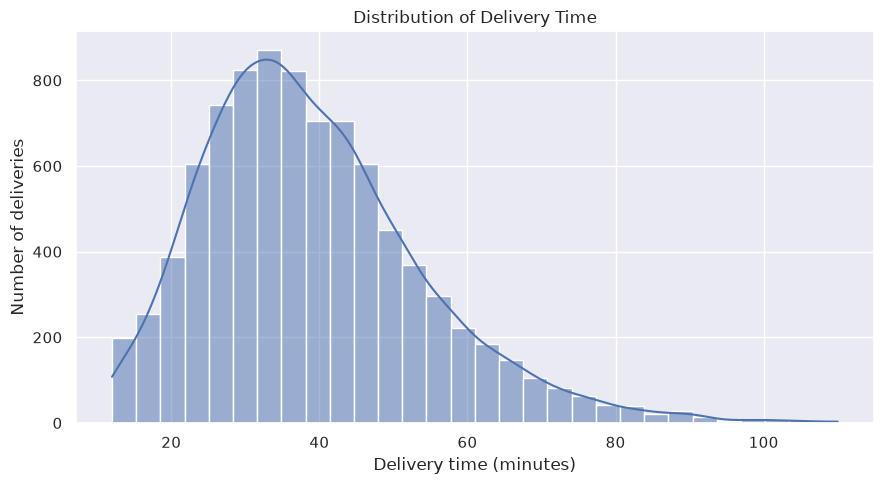

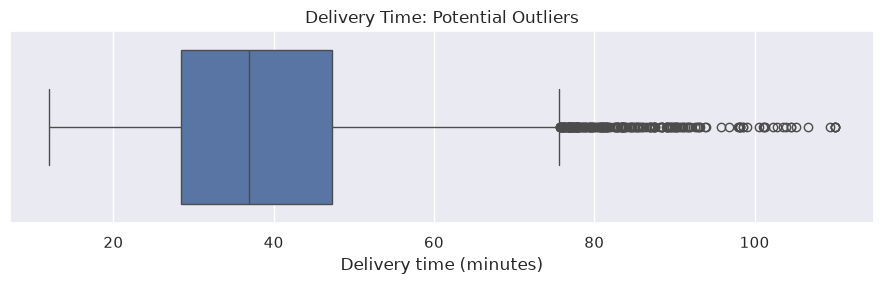

Target summary:


,value
count,8808.000000
mean,39.060854
std,14.970225
min,12.000000
25%,28.400000
50%,36.900000
75%,47.300000
max,110.000000


IQR lower bound: 0.05
IQR upper bound: 75.65
Potential outliers: 204 (2.32%)


In [7]:
# A histogram shows common delivery-time ranges and whether the target is skewed.
plt.figure(figsize=(9, 5))
sns.histplot(model_df[target_col], bins=30, kde=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of deliveries")
plt.tight_layout()
plt.show()

# A box plot highlights values that may deserve further investigation.
plt.figure(figsize=(9, 3))
sns.boxplot(x=model_df[target_col])
plt.title("Delivery Time: Potential Outliers")
plt.xlabel("Delivery time (minutes)")
plt.tight_layout()
plt.show()

# Use the IQR rule to count potential outliers; this is an investigation flag only.
q1 = model_df[target_col].quantile(0.25)
q3 = model_df[target_col].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
potential_outliers = model_df[
    (model_df[target_col] < lower_bound) | (model_df[target_col] > upper_bound)
]

print("Target summary:")
display(model_df[target_col].describe().to_frame("value"))
print(f"IQR lower bound: {lower_bound:.2f}")
print(f"IQR upper bound: {upper_bound:.2f}")
print(f"Potential outliers: {len(potential_outliers)} ({len(potential_outliers)/len(model_df)*100:.2f}%)")

### Observation

The average delivery time is 39.06 minutes, with a median of 36.90 minutes. Values range from 12 to 110 minutes, and 204 records (2.32%) were identified as potential outliers.

The target contains some unusually long deliveries that may affect prediction errors. We will investigate relationships between delivery time and available features.

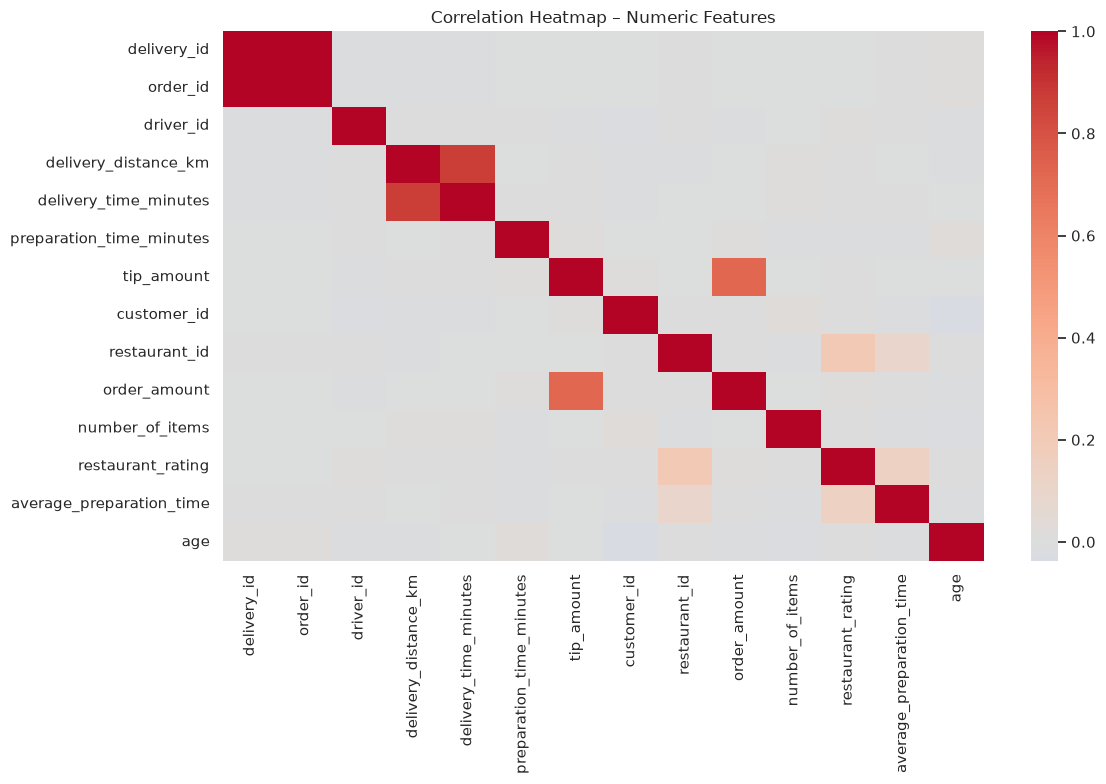

,correlation_with_target
delivery_distance_km,0.867665
number_of_items,0.012890
delivery_id,-0.012270
order_id,-0.012263
customer_id,-0.011223
average_preparation_time,0.008346
driver_id,0.008173
tip_amount,0.007974
restaurant_rating,0.005523
preparation_time_minutes,0.005291


In [8]:
# Correlations show the strength and direction of linear relationships between numeric columns.
numeric_df = model_df.select_dtypes(include=np.number)
correlation_df = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_df, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap – Numeric Features")
plt.tight_layout()
plt.show()

# Display numeric correlations with the target, ordered by absolute magnitude.
if target_col in correlation_df.columns:
    target_correlations = correlation_df[target_col].drop(target_col).sort_values(
        key=lambda values: values.abs(), ascending=False
    )
    display(target_correlations.to_frame("correlation_with_target"))

### Observation – Correlation

Delivery distance has a strong positive correlation with delivery time (0.868). Other displayed numeric features have much weaker linear correlations.

The scatter plots below provide a closer look at available candidate predictors.

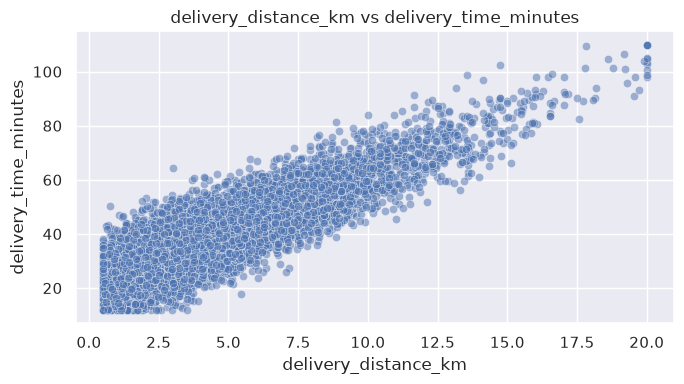

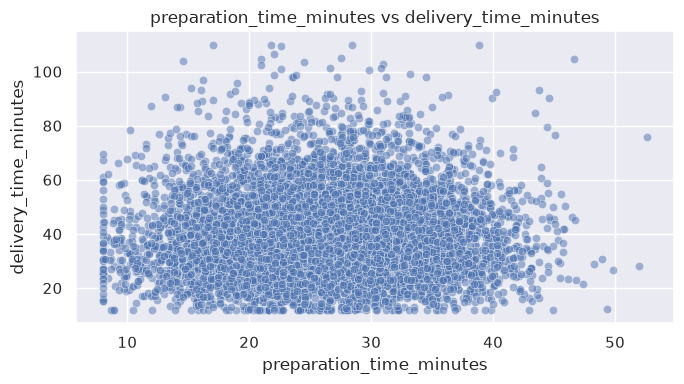

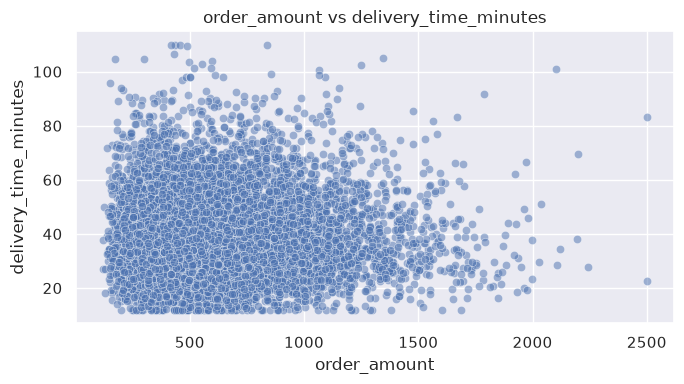

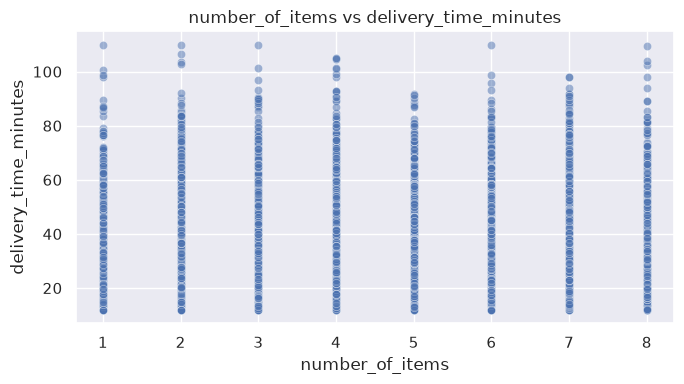

In [9]:
# Plot only candidate numeric features that actually exist in the dataset.
scatter_candidates = [
    "delivery_distance_km", "distance_km", "distance",
    "preparation_time_minutes", "prep_time_minutes",
    "order_amount", "total_amount", "number_of_items", "item_count"
]
scatter_features = [
    col for col in scatter_candidates
    if col in model_df.columns and col != target_col
    and pd.api.types.is_numeric_dtype(model_df[col])
]
scatter_features = list(dict.fromkeys(scatter_features))

if scatter_features:
    for feature in scatter_features[:4]:
        plot_df = model_df[[feature, target_col]].dropna()
        if not plot_df.empty:
            plt.figure(figsize=(7, 4))
            sns.scatterplot(data=plot_df, x=feature, y=target_col, alpha=0.5)
            plt.title(f"{feature} vs {target_col}")
            plt.tight_layout()
            plt.show()
else:
    print("No candidate numeric features were found for scatter plots.")
    print("Inspect model_df.columns and update scatter_candidates if needed.")

### Observation – Scatter plots

Describe visible trends, clusters, or unusual points. These charts are exploratory; the model evaluation will show whether the chosen features help predict unseen delivery times.

## 6. Feature engineering and leakage checks

We select available predictors from a candidate list. For a prediction made when the order is placed, we must exclude fields that reveal the final delivery outcome, such as the target itself or post-delivery timestamps/statuses. IDs are excluded because they usually do not provide reusable operational information.

In [10]:
# Potential numeric predictors; only available and numeric columns are retained.
numeric_candidates = [
    "delivery_distance_km", "distance_km", "distance",
    "order_amount", "total_amount", "subtotal",
    "number_of_items", "item_count", "preparation_time_minutes",
    "prep_time_minutes", "restaurant_rating", "rating",
    "reliability_score"
]
categorical_candidates = [
    "traffic", "traffic_level", "weather", "weather_condition",
    "time_of_day", "day_of_week", "restaurant_category",
    "customer_segment", "payment_method"
]

# Remove IDs and fields that can reveal the completed delivery outcome.
leakage_terms = [
    "id", "delivery_time", "duration", "delivered_at", "delivery_timestamp",
    "completed_at", "status", "actual_arrival", "arrival_time"
]

numeric_features = [
    col for col in numeric_candidates
    if col in model_df.columns and col != target_col
    and pd.api.types.is_numeric_dtype(model_df[col])
    and not any(term in col.lower() for term in leakage_terms if term != "id")
]
categorical_features = [
    col for col in categorical_candidates
    if col in model_df.columns and col != target_col
    and not any(term in col.lower() for term in leakage_terms)
]
numeric_features = list(dict.fromkeys(numeric_features))
categorical_features = list(dict.fromkeys(categorical_features))
feature_cols = numeric_features + categorical_features

print("Numeric features selected:", numeric_features)
print("Categorical features selected:", categorical_features)

if not feature_cols:
    raise ValueError(
        "No candidate predictor columns were found. Inspect model_df.columns and update "
        "numeric_candidates/categorical_candidates to match the actual dataset."
    )

modeling_data = model_df[feature_cols + [target_col]].copy()
X = modeling_data[feature_cols]
y = modeling_data[target_col].astype(float)

print("Feature matrix shape:", X.shape)
print("Target length:", len(y))
display(modeling_data.head())

Numeric features selected: ['delivery_distance_km', 'order_amount', 'number_of_items', 'preparation_time_minutes', 'restaurant_rating']
Categorical features selected: ['weather_condition', 'restaurant_category', 'payment_method']
Feature matrix shape: (8808, 8)
Target length: 8808


,delivery_distance_km,order_amount,number_of_items,preparation_time_minutes,restaurant_rating,weather_condition,restaurant_category,payment_method,delivery_time_minutes
0,2.83,165.09,2,16.0,4.21,Clear,Indian,UPI,36.0
1,2.00,369.44,4,17.5,3.75,Clear,Pizza,UPI,30.4
2,2.85,349.26,7,25.7,4.61,Rain,Burgers,UPI,39.5
3,2.97,379.08,7,31.9,4.53,Clear,Indian,Card,26.8
4,2.47,1343.82,7,33.2,3.75,Rain,Pizza,Card,35.5


### Observation – Feature selection

Eight predictors were selected: five numeric and three categorical features. The data was divided into 7,046 training records and 1,762 testing records.

The data is prepared for supervised regression. The separate test set will help evaluate predictions on unseen records.

In [11]:
# Split data before fitting preprocessing steps to avoid leaking test-set information.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Numeric preprocessing for Ridge/Lasso: impute missing values, then scale.
numeric_transformer_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numeric preprocessing for tree/baseline models does not require scaling.
numeric_transformer_unscaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing: fill missing categories and one-hot encode them.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer_scaled, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

preprocessor_unscaled = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer_unscaled, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Train/test split complete.")

Training records: 7046
Testing records: 1762
Train/test split complete.


## 7. Evaluation metrics: MAE, RMSE, and R²

All models will be evaluated on the same held-out test records.

- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted delivery times. It is measured in minutes; lower is better.
- **RMSE (Root Mean Squared Error):** Also measured in minutes, but it penalizes large errors more heavily. Lower is better.
- **R² (R-squared):** Measures performance relative to predicting the mean target value. A value closer to 1 is generally better; 0 means no improvement over that reference, and a negative score means worse performance on the evaluated data.


## 8. Baseline model

The baseline is a simple reference point. `DummyRegressor` predicts the mean delivery time from the training data for every test record.

In [12]:
# Fit a mean-prediction baseline using the same preprocessing pipeline structure.
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor_unscaled),
    ("model", DummyRegressor(strategy="mean"))
])
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

def evaluate_regression_model(model_name, y_true, y_pred):
    # Keep metric calculation consistent across all models.
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_result = evaluate_regression_model("Baseline (Mean)", y_test, baseline_predictions)
display(pd.DataFrame([baseline_result]).round(3))

,Model,MAE,RMSE,R2
0,Baseline (Mean),11.702,14.848,-0.0


### Baseline observation

The baseline achieved an MAE of 11.702 minutes, an RMSE of 14.848 minutes, and an R² score close to zero.

The baseline provides a reference for comparison. More advanced models should reduce prediction errors by learning from the available features.

## 9. Model 1 – Random Forest Regressor

Random Forest combines many decision trees. Each tree learns decision rules from randomized samples of training data and features, and the forest averages their predictions for regression.


In [13]:
# Build preprocessing and Random Forest into one reusable pipeline.
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor_unscaled),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
random_forest_model.fit(X_train, y_train)

rf_train_predictions = random_forest_model.predict(X_train)
rf_test_predictions = random_forest_model.predict(X_test)

rf_result = evaluate_regression_model("Random Forest", y_test, rf_test_predictions)
rf_train_result = evaluate_regression_model("Random Forest (Train)", y_train, rf_train_predictions)
display(pd.DataFrame([rf_result, rf_train_result]).round(3))

,Model,MAE,RMSE,R2
0,Random Forest,5.555,6.905,0.784
1,Random Forest (Train),2.504,3.215,0.954


### Random Forest observation

Random Forest achieved a test MAE of 5.555 minutes, RMSE of 6.905 minutes, and R² of 0.784. Training error was substantially lower than test error.

Random Forest improved considerably over the baseline but showed signs of overfitting. We will compare it with regularized linear models.

## 10. Model 2 – Ridge Regression

Ridge is linear regression with L2 regularization. It discourages excessively large coefficients, which can improve stability when features overlap or are correlated. 

In [14]:
# Train Ridge with preprocessing fitted only on training data.
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor_scaled),
    ("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)

ridge_train_predictions = ridge_model.predict(X_train)
ridge_test_predictions = ridge_model.predict(X_test)

ridge_result = evaluate_regression_model("Ridge Regression", y_test, ridge_test_predictions)
ridge_train_result = evaluate_regression_model("Ridge Regression (Train)", y_train, ridge_train_predictions)
display(pd.DataFrame([ridge_result, ridge_train_result]).round(3))

,Model,MAE,RMSE,R2
0,Ridge Regression,5.437,6.739,0.794
1,Ridge Regression (Train),5.438,6.734,0.798


### Ridge Regression observation

Ridge achieved a test MAE of 5.437 minutes, RMSE of 6.739 minutes, and R² of 0.794. Training and test performance were very similar.

Ridge slightly outperformed Random Forest on the test set and showed consistent performance. Next, we evaluate Lasso Regression.

## 11. Model 3 – Lasso Regression

Lasso uses L1 regularization. Like Ridge, it controls coefficient size, but it can shrink some coefficients to zero, effectively removing some encoded features from the linear model.

In [15]:
# Train Lasso; alpha controls the strength of regularization.
lasso_model = Pipeline(steps=[
    ("preprocessor", preprocessor_scaled),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])
lasso_model.fit(X_train, y_train)

lasso_train_predictions = lasso_model.predict(X_train)
lasso_test_predictions = lasso_model.predict(X_test)

lasso_result = evaluate_regression_model("Lasso Regression", y_test, lasso_test_predictions)
lasso_train_result = evaluate_regression_model("Lasso Regression (Train)", y_train, lasso_train_predictions)
display(pd.DataFrame([lasso_result, lasso_train_result]).round(3))

,Model,MAE,RMSE,R2
0,Lasso Regression,5.439,6.741,0.794
1,Lasso Regression (Train),5.438,6.734,0.798


### Lasso Regression observation

Lasso achieved a test MAE of 5.439 minutes, RMSE of 6.741 minutes, and R² of 0.794. Its training and test metrics were nearly identical.

Lasso performed almost identically to Ridge, making it a competitive alternative. We will compare all models to select the preferred approach.

## 12. Compare all models

This table brings together the baseline and the three regression models. Lower MAE and RMSE mean smaller prediction errors; higher R² is generally better.

In [16]:
# Compare every fitted model using predictions on the same test rows.
predictions_by_model = {
    "Baseline (Mean)": baseline_predictions,
    "Random Forest": rf_test_predictions,
    "Ridge Regression": ridge_test_predictions,
    "Lasso Regression": lasso_test_predictions
}
comparison_rows = [
    evaluate_regression_model(name, y_test, predictions)
    for name, predictions in predictions_by_model.items()
]
comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by=["MAE", "RMSE"], ascending=True
).reset_index(drop=True)

display(comparison_df.round(3))
comparison_df.to_csv(reports_dir / "model_comparison.csv", index=False)
print("Saved model comparison to:", reports_dir / "model_comparison.csv")

,Model,MAE,RMSE,R2
0,Ridge Regression,5.437,6.739,0.794
1,Lasso Regression,5.439,6.741,0.794
2,Random Forest,5.555,6.905,0.784
3,Baseline (Mean),11.702,14.848,-0.000


Saved model comparison to: /home/nineleaps-admin/uber-eats-intelligence/reports/day4/model_comparison.csv


### Model comparison – conclusion

Ridge achieved the lowest test MAE (5.437 minutes), lowest RMSE (6.739 minutes), and highest R² (0.794). Lasso performed almost identically, while Random Forest had slightly higher errors.

Ridge is the preferred model based on the test results. It reduced MAE by approximately 6.265 minutes compared with the baseline.

In [17]:
# Select the lowest-MAE model and describe its performance relative to baseline.
best_row = comparison_df.sort_values(["MAE", "RMSE"], ascending=True).iloc[0]
best_model_name = best_row["Model"]

print(f"Lowest-MAE model on the test set: {best_model_name}")
print(f"MAE:  {best_row['MAE']:.3f} minutes")
print(f"RMSE: {best_row['RMSE']:.3f} minutes")
print(f"R²:   {best_row['R2']:.3f}")

baseline_row = comparison_df.loc[comparison_df["Model"] == "Baseline (Mean)"].iloc[0]
mae_improvement = baseline_row["MAE"] - best_row["MAE"]

if best_model_name != "Baseline (Mean)" and mae_improvement > 0:
    print(
        f"Conclusion: {best_model_name} improved on the baseline by "
        f"{mae_improvement:.3f} minutes in MAE on this test split."
    )
elif best_model_name == "Baseline (Mean)":
    print(
        "Conclusion: The mean baseline has the lowest MAE. The current features/models "
        "have not demonstrated better MAE on this test split."
    )
else:
    print(
        "Conclusion: The selected model did not improve MAE over the baseline. "
        "Review feature quality, leakage checks, and model settings before recommending it."
    )

Lowest-MAE model on the test set: Ridge Regression
MAE:  5.437 minutes
RMSE: 6.739 minutes
R²:   0.794
Conclusion: Ridge Regression improved on the baseline by 6.265 minutes in MAE on this test split.


## 13. Actual vs predicted delivery times

This scatter plot compares the selected model's predictions with actual delivery times. Points close to the diagonal reference line are more accurate; points farther away represent larger errors.

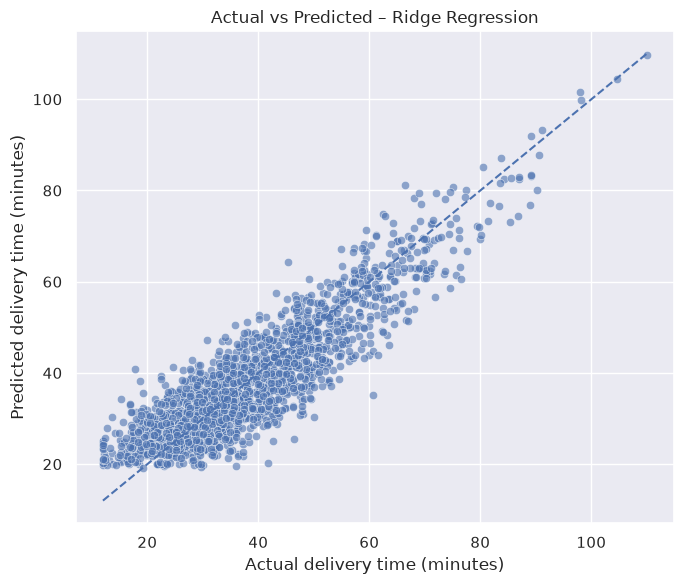

In [18]:
# Retrieve the fitted model and its predictions based on the model comparison.
fitted_models = {
    "Baseline (Mean)": baseline_model,
    "Random Forest": random_forest_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}
best_model = fitted_models[best_model_name]
best_predictions = predictions_by_model[best_model_name]

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.6)
plot_min = min(float(y_test.min()), float(np.min(best_predictions)))
plot_max = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--")
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.tight_layout()
plt.show()

### Actual vs predicted – conclusion

Ridge achieved a test MAE of 5.437 minutes and RMSE of 6.739 minutes, indicating relatively small average prediction errors.

Points closer to the diagonal represent more accurate predictions. Inspect the plot for larger errors, particularly among longer deliveries.

## 14. Residual analysis

A residual is the actual value minus the predicted value. Positive residuals mean the delivery took longer than predicted; negative residuals mean the model predicted a longer duration than actually occurred.

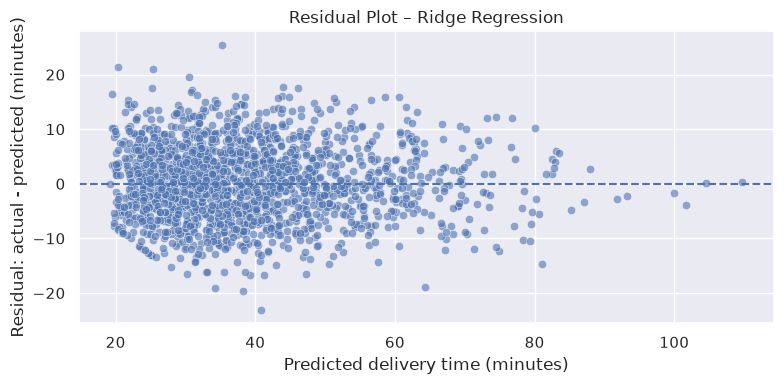

Mean residual: 0.327
Median absolute residual: 4.716


In [19]:
# Check whether prediction errors show a pattern.
residuals = y_test - best_predictions

plt.figure(figsize=(8, 4))
sns.scatterplot(x=best_predictions, y=residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted delivery time (minutes)")
plt.ylabel("Residual: actual - predicted (minutes)")
plt.title(f"Residual Plot – {best_model_name}")
plt.tight_layout()
plt.show()

print("Mean residual:", round(float(residuals.mean()), 3))
print("Median absolute residual:", round(float(np.median(np.abs(residuals))), 3))

### Residual analysis observation

The mean residual was 0.327 minutes, while the median absolute residual was 4.716 minutes. The small positive mean indicates slight overall underprediction.

The model's average signed error is small, but individual predictions can still differ from actual delivery times. The residual plot helps identify systematic errors.

## 15. Cross-validation on the training set

A single split can depend on which records happen to land in the test set. Five-fold cross-validation evaluates performance across several folds of the training data.

In [20]:
# Cross-validation uses only training data. Pipelines refit preprocessing within each fold.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in fitted_models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )
    mae_scores = -scores
    cv_rows.append({
        "Model": name,
        "CV_MAE_mean": mae_scores.mean(),
        "CV_MAE_std": mae_scores.std()
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("CV_MAE_mean").reset_index(drop=True)
display(cv_results_df.round(3))
cv_results_df.to_csv(reports_dir / "cross_validation_mae.csv", index=False)
print("Saved cross-validation results to:", reports_dir / "cross_validation_mae.csv")

,Model,CV_MAE_mean,CV_MAE_std
0,Lasso Regression,5.448,0.071
1,Ridge Regression,5.450,0.071
2,Random Forest,5.645,0.068
3,Baseline (Mean),11.664,0.224


Saved cross-validation results to: /home/nineleaps-admin/uber-eats-intelligence/reports/day4/cross_validation_mae.csv


### Cross-validation – conclusion

Lasso achieved the lowest mean cross-validation MAE at 5.448 minutes, followed closely by Ridge at 5.450 minutes. Random Forest recorded 5.645 minutes.

Ridge and Lasso showed very similar cross-validation performance. Ridge remains the preferred model based on the held-out test metrics, although the difference is minimal.

## 16. Random Forest feature importance

Random Forest provides impurity-based feature importance scores. We map the scores to the transformed feature names, including one-hot encoded categories. These scores are useful for interpretation but do not prove causation.

,feature,importance
0,numeric__delivery_distance_km,0.8106
1,numeric__order_amount,0.0365
2,numeric__preparation_time_minutes,0.0363
3,categorical__weather_condition_Rain,0.0345
4,numeric__restaurant_rating,0.0288
5,numeric__number_of_items,0.0172
6,categorical__weather_condition_Clear,0.0070
7,categorical__payment_method_UPI,0.0037
8,categorical__payment_method_Card,0.0032
9,categorical__restaurant_category_Desserts,0.0031


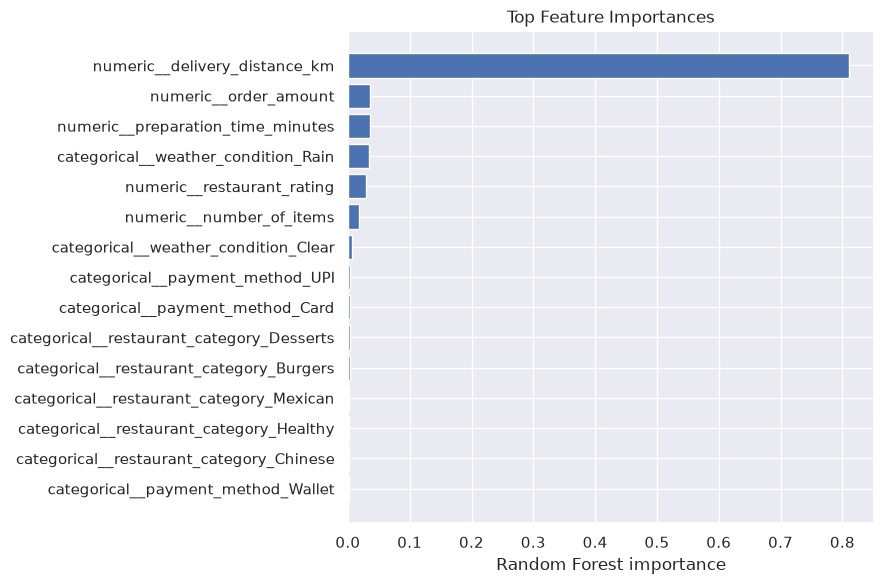

Saved feature importance to: /home/nineleaps-admin/uber-eats-intelligence/reports/day4/random_forest_feature_importance.csv


In [21]:
# Extract transformed feature names and rank Random Forest importance scores.
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_estimator = random_forest_model.named_steps["model"]

try:
    transformed_feature_names = rf_preprocessor.get_feature_names_out()
    importances = rf_estimator.feature_importances_
    feature_importance_df = pd.DataFrame({
        "feature": transformed_feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False).reset_index(drop=True)

    display(feature_importance_df.head(15).round(4))
    feature_importance_df.to_csv(reports_dir / "random_forest_feature_importance.csv", index=False)

    top_features = feature_importance_df.head(15).sort_values("importance")
    plt.figure(figsize=(9, 6))
    plt.barh(top_features["feature"], top_features["importance"])
    plt.xlabel("Random Forest importance")
    plt.title("Top Feature Importances")
    plt.tight_layout()
    plt.show()

    print("Saved feature importance to:", reports_dir / "random_forest_feature_importance.csv")
except Exception as error:
    print("Could not extract feature importance automatically:", error)
    print("Check your scikit-learn version and transformed feature names.")

### Feature importance – conclusion

Delivery distance had the highest feature importance (0.8106), followed by order amount, preparation time, and rainy weather.

## 17. Save model and deliverables

We save the selected fitted pipeline so it includes the preprocessing steps needed for future predictions. We also save the feature-engineered modeling data, model comparison, cross-validation results, feature importance, and actual-versus-predicted values.


In [22]:
# Save the selected fitted pipeline, including its preprocessing steps.
model_output_path = models_dir / "delivery_time_regression_pipeline.joblib"
joblib.dump(best_model, model_output_path)

# Save the modeling dataset and prediction details for review.
modeling_data.to_csv(processed_dir / "delivery_time_modeling_dataset.csv", index=False)

prediction_output = pd.DataFrame({
    "actual_delivery_time_minutes": y_test.to_numpy(),
    "predicted_delivery_time_minutes": np.asarray(best_predictions),
    "residual_minutes": np.asarray(y_test) - np.asarray(best_predictions)
})
prediction_output.to_csv(reports_dir / "actual_vs_predicted.csv", index=False)

# Ensure the comparison is saved.
comparison_df.to_csv(reports_dir / "model_comparison.csv", index=False)

print("Saved model:", model_output_path)
print("Saved modeling dataset:", processed_dir / "delivery_time_modeling_dataset.csv")
print("Saved predictions:", reports_dir / "actual_vs_predicted.csv")
print("Saved comparison:", reports_dir / "model_comparison.csv")

Saved model: /home/nineleaps-admin/uber-eats-intelligence/models/day4/delivery_time_regression_pipeline.joblib
Saved modeling dataset: /home/nineleaps-admin/uber-eats-intelligence/data/processed/delivery_time_modeling_dataset.csv
Saved predictions: /home/nineleaps-admin/uber-eats-intelligence/reports/day4/actual_vs_predicted.csv
Saved comparison: /home/nineleaps-admin/uber-eats-intelligence/reports/day4/model_comparison.csv


## 18. Final Business Insights

Delivery time: Average duration was 39.06 minutes, with 204 potential outliers.

Key predictor: Delivery distance showed a strong positive correlation with delivery time (0.868).

Best model: Ridge achieved an MAE of 5.437 minutes, RMSE of 6.739 minutes, and R² of 0.794.

Model comparison: Ridge slightly outperformed Lasso and Random Forest on the test set.

Recommendation: Ridge is the preferred model based on the current results. Further validation on real-world data is needed before operational use.